# Taller final de Minería de Datos
## Segmentación de clientes con K-Means

**Estudiante:** ____________________ &nbsp;&nbsp; **Fecha:** ____________

**Dataset:** Mall Customers ([Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python))

**Objetivo general:** desarrollar un modelo de segmentación de clientes con K-Means, usando el método del codo y el coeficiente de silueta para elegir el número de clusters, e interpretar los grupos desde una perspectiva de negocio para apoyar decisiones de marketing.

**Estructura del proyecto**

| Carpeta | Contenido |
|---|---|
| `datos/` | Dataset original y dataset con clusters asignados |
| `cuaderno/` | Este cuaderno (análisis + respuestas) |
| `entrenamiento/` | Script que entrena y exporta el modelo |
| `modelo/` | Modelo K-Means, scaler y metadatos |
| `frontend/` | Aplicación Streamlit (despliegue) |

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.precision", 2)

RANDOM_STATE = 42
COLORES = {
    "Clientes de alto valor": "#1B7F5C",
    "Clientes con potencial": "#D08C1A",
    "Clientes promedio": "#6B7C8F",
    "Clientes impulsivos": "#7A4FA3",
    "Clientes de bajo valor": "#B5404E",
}

---
# Parte 1 – Exploración de datos
### 1.1 Cargar el dataset

In [2]:
RUTA_DATOS = Path("../datos/Mall_Customers.csv")
if not RUTA_DATOS.exists():               # por si el cuaderno se abre desde la raíz
    RUTA_DATOS = Path("datos/Mall_Customers.csv")

df = pd.read_csv(RUTA_DATOS)
print("Dimensiones:", df.shape)
df.head(10)

Dimensiones: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


### 1.2 Identificar variables relevantes

| Variable | Tipo | ¿Útil para segmentar? |
|---|---|---|
| `CustomerID` | Identificador | No, es solo un consecutivo |
| `Gender` | Categórica | Poco, se analiza abajo |
| `Age` | Numérica | Parcialmente |
| `Annual Income (k$)` | Numérica | Sí, capacidad de compra |
| `Spending Score (1-100)` | Numérica | Sí, comportamiento de gasto |

### 1.3 Análisis descriptivo básico

In [4]:
num = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
print("Valores nulos por columna:\n", df.isna().sum(), sep="")
print("\nFilas duplicadas:", df.duplicated().sum())
df[num].describe().T

Valores nulos por columna:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Filas duplicadas: 0


,count,mean,std,min,25%,50%,75%,max
Age,200.0,38.85,13.97,18.0,28.75,36.0,49.0,70.0
Annual Income (k$),200.0,60.56,26.26,15.0,41.50,61.5,78.0,137.0
Spending Score (1-100),200.0,50.20,25.82,1.0,34.75,50.0,73.0,99.0


In [5]:
print(df["Gender"].value_counts())
print()
print("Promedios por género:")
df.groupby("Gender")[num].mean().round(1)

Gender
Female    112
Male       88
Name: count, dtype: int64

Promedios por género:


,Age,Annual Income (k$),Spending Score (1-100)
Gender,,,
Female,38.1,59.2,51.5
Male,39.8,62.2,48.5


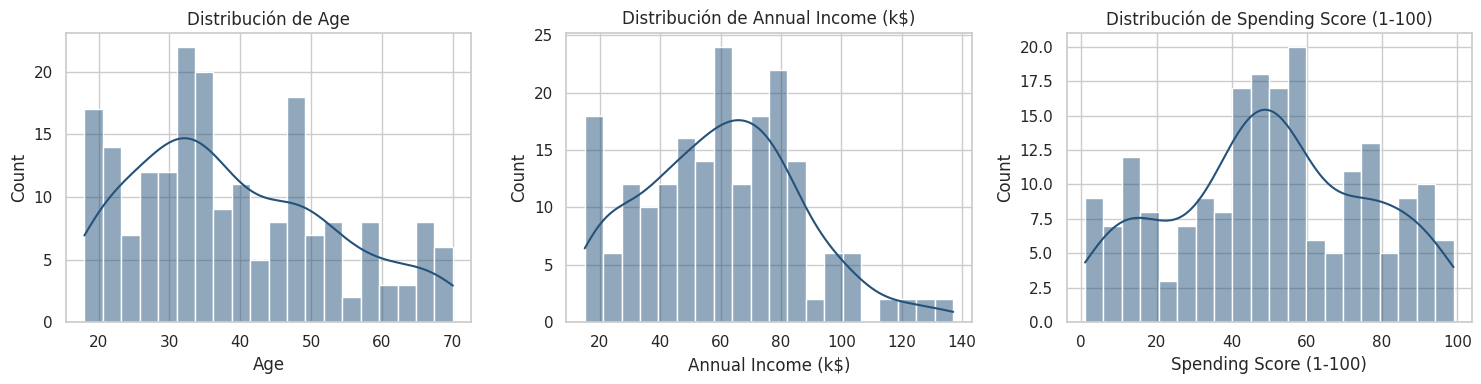

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num):
    sns.histplot(df[col], bins=20, kde=True, ax=ax, color="#24527A")
    ax.set_title(f"Distribución de {col}")
plt.tight_layout()
plt.show()

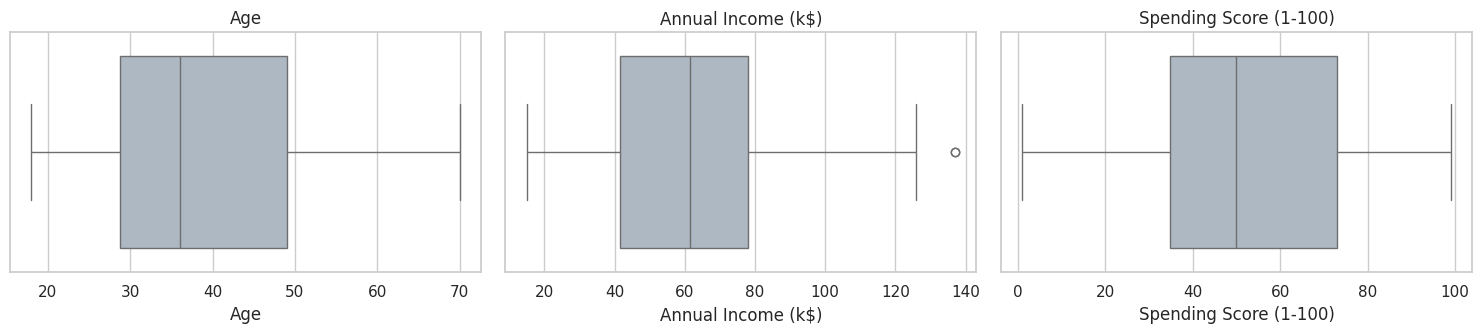

,Variable,Límite inferior,Límite superior,N.º atípicos,Valores
0,Age,-1.62,79.38,0,[]
1,Annual Income (k$),-13.25,132.75,2,"[137, 137]"
2,Spending Score (1-100),-22.62,130.38,0,[]


In [7]:
# Detección de valores atípicos con boxplot y regla del rango intercuartílico (IQR)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col in zip(axes, num):
    sns.boxplot(x=df[col], ax=ax, color="#A9B8C7")
    ax.set_title(col)
plt.tight_layout()
plt.show()

filas = []
for col in num:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    atipicos = df[(df[col] < lim_inf) | (df[col] > lim_sup)][col]
    filas.append({"Variable": col, "Límite inferior": lim_inf, "Límite superior": lim_sup,
                  "N.º atípicos": len(atipicos), "Valores": atipicos.tolist()})
pd.DataFrame(filas)

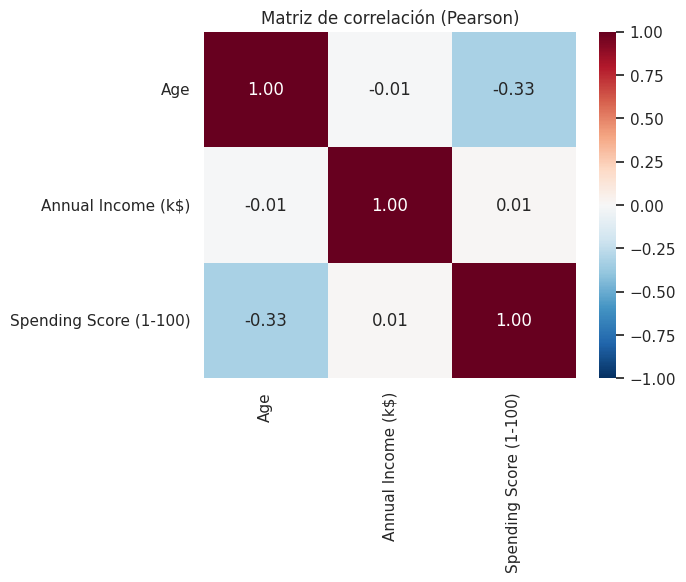

In [8]:
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(df[num].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Matriz de correlación (Pearson)")
plt.show()

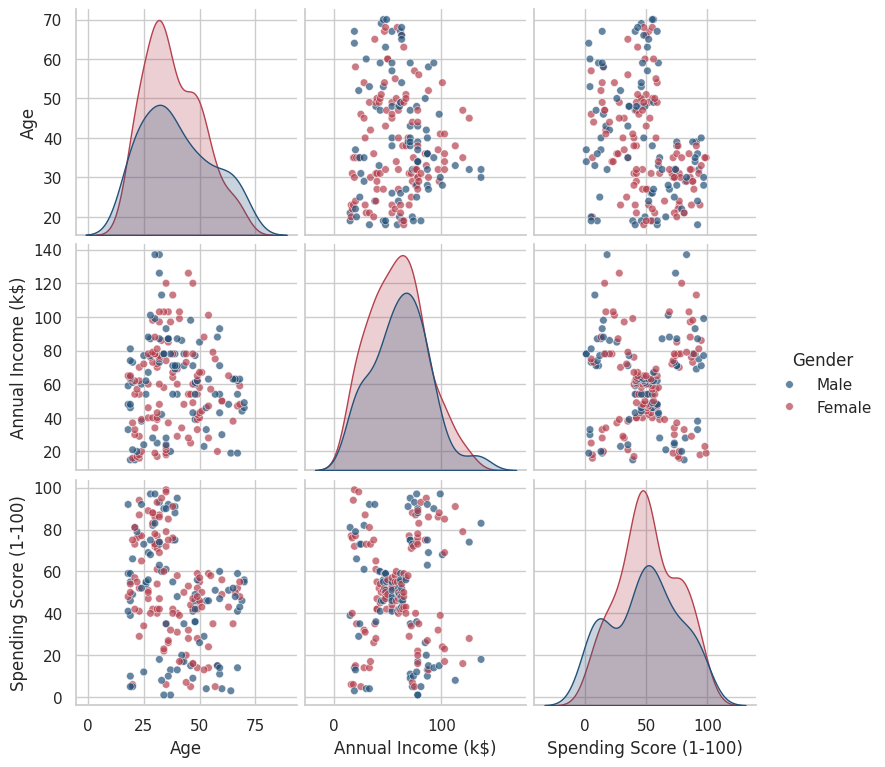

In [9]:
sns.pairplot(df, vars=num, hue="Gender", palette={"Female": "#B5404E", "Male": "#24527A"},
             plot_kws={"alpha": 0.7, "s": 30}, height=2.6)
plt.show()

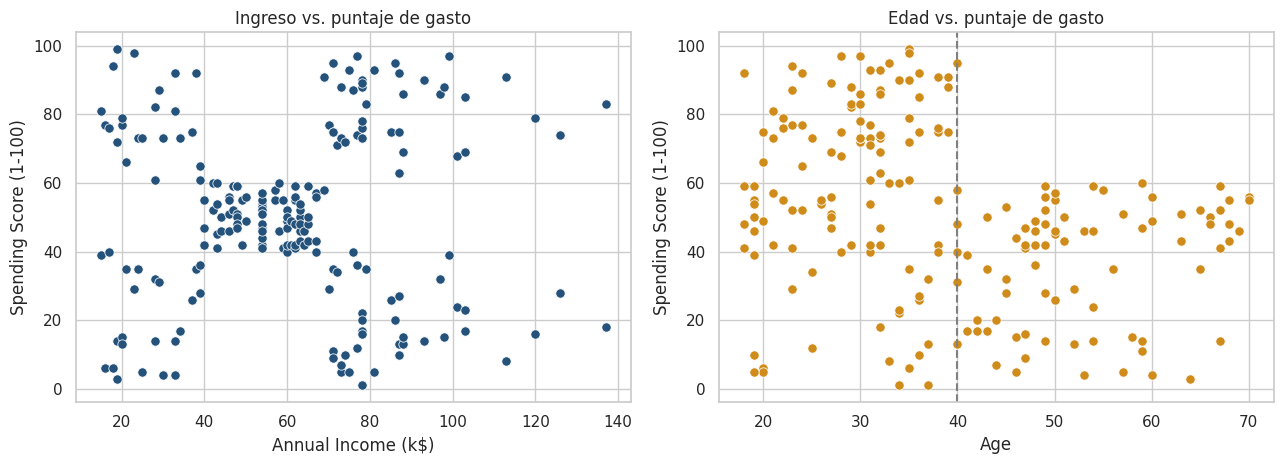

Gasto máximo en mayores de 40 años: 60
Gasto promedio <= 40 años: 59.3
Gasto promedio  > 40 años: 36.0


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)",
                ax=axes[0], color="#24527A", s=45)
axes[0].set_title("Ingreso vs. puntaje de gasto")
sns.scatterplot(data=df, x="Age", y="Spending Score (1-100)",
                ax=axes[1], color="#D08C1A", s=45)
axes[1].axvline(40, ls="--", c="grey")
axes[1].set_title("Edad vs. puntaje de gasto")
plt.tight_layout()
plt.show()

print("Gasto máximo en mayores de 40 años:", df.loc[df.Age > 40, "Spending Score (1-100)"].max())
print("Gasto promedio <= 40 años:", round(df.loc[df.Age <= 40, "Spending Score (1-100)"].mean(), 1))
print("Gasto promedio  > 40 años:", round(df.loc[df.Age > 40, "Spending Score (1-100)"].mean(), 1))

### ❓ Pregunta 1.1: ¿Qué variables son más adecuadas para segmentar clientes?

Las más adecuadas son **`Annual Income (k$)`** y **`Spending Score (1-100)`**:

- Son numéricas continuas, que es lo que necesita K-Means porque trabaja con distancias euclidianas.
- Tienen sentido de negocio directo: una mide **cuánto puede gastar** el cliente y la otra **cuánto gasta realmente** en el centro comercial.
- Su correlación es prácticamente nula (r ≈ 0.01), así que cada una aporta información distinta, y en el diagrama de dispersión se ven a simple vista **5 nubes de puntos** separadas.

Las demás variables se descartan para el modelo principal:

- `CustomerID` es un identificador sin significado.
- `Gender` es categórica y casi no discrimina: hombres y mujeres tienen ingreso y gasto promedio muy parecidos (gasto 48.5 vs. 51.5).
- `Age` sí aporta algo (se relaciona con el gasto), pero al incluirla los grupos quedan menos definidos: la silueta máxima baja de 0.55 a ≈ 0.43 (se comprueba en la Parte 4). Por eso se usa para **describir** los clusters, no para formarlos.

### ❓ Pregunta 1.2: ¿Se identifican valores atípicos?

Con la regla del IQR solo aparecen **2 valores atípicos**, ambos en `Annual Income (k$)` (dos clientes con 137 k$, por encima del límite de 132.75 k$). `Age` y `Spending Score` no tienen atípicos, y no hay valores nulos ni filas duplicadas.

Estos dos clientes **no se eliminan**: no son errores de captura sino clientes reales de ingreso muy alto, justamente un perfil que interesa al negocio. Además, al estar estandarizados, su efecto sobre los centroides es pequeño dentro de un grupo de 39 clientes.

### ❓ Pregunta 1.3: ¿Qué tipo de relaciones se observan entre las variables?

- **Ingreso vs. gasto:** no hay relación lineal (r ≈ 0.01), pero sí una **estructura de grupos** muy marcada. Tener más ingreso no implica gastar más: hay personas de ingreso alto que gastan poco y personas de ingreso bajo que gastan mucho. Esta es la relación más útil para segmentar.
- **Edad vs. gasto:** relación **negativa moderada** (r ≈ -0.33). Los clientes jóvenes gastan más; de hecho, ningún cliente mayor de 40 años supera un puntaje de gasto de 60, y el gasto promedio cae de 59 (≤ 40 años) a 36 (> 40 años).
- **Edad vs. ingreso:** sin relación (r ≈ -0.01).
- **Género:** las distribuciones de hombres y mujeres se superponen casi por completo, sin diferencias relevantes.

---
# Parte 2 – Preprocesamiento
Se aplica `StandardScaler` a las variables elegidas, transformando cada una a media 0 y desviación estándar 1:

$$z = \frac{x - \mu}{\sigma}$$

In [11]:
FEATURES = ["Annual Income (k$)", "Spending Score (1-100)"]
X_original = df[FEATURES]

scaler = StandardScaler()
X = scaler.fit_transform(X_original)

comparacion = pd.DataFrame({
    "Media original": X_original.mean(),
    "Desv. original": X_original.std(ddof=0),
    "Rango original": X_original.max() - X_original.min(),
    "Media escalada": X.mean(axis=0).round(4),
    "Desv. escalada": X.std(axis=0).round(4),
})
comparacion

,Media original,Desv. original,Rango original,Media escalada,Desv. escalada
Annual Income (k$),60.56,26.20,122,-0.0,1.0
Spending Score (1-100),50.20,25.76,98,-0.0,1.0


### ❓ Pregunta 2.1: ¿Por qué es necesario escalar las variables en el algoritmo K-Means?

Porque K-Means asigna cada punto al centroide más cercano usando la **distancia euclidiana**, y esa distancia depende de las unidades de cada variable. Si una variable tiene valores más grandes o más dispersos, sus diferencias pesan más en la distancia y termina **dominando la formación de los clusters**, aunque no sea más importante.

Por ejemplo, si el ingreso estuviera en pesos colombianos (millones) y el puntaje de gasto de 1 a 100, el algoritmo prácticamente ignoraría el gasto. Al estandarizar, ambas variables quedan en la misma escala (media 0, desviación 1) y contribuyen por igual.

En este dataset las dos variables tienen desviaciones parecidas (≈ 26), pero escalar sigue siendo buena práctica: hace el modelo independiente de las unidades y obliga a guardar el `scaler`, que luego se usa en la app para transformar a los clientes nuevos **exactamente igual** que a los datos de entrenamiento.

---
# Parte 3 – Método del codo
Se entrena K-Means para K = 1 a 10 y se registra la **inercia** (WCSS, *within-cluster sum of squares*): la suma de las distancias al cuadrado de cada punto a su centroide.

In [12]:
rango_k = range(1, 11)
inercias = []
for k in rango_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    inercias.append(km.inertia_)

tabla_codo = pd.DataFrame({"K": list(rango_k), "Inercia": inercias})
tabla_codo["Reducción vs. K-1 (%)"] = (-tabla_codo["Inercia"].pct_change() * 100).round(1)
tabla_codo

,K,Inercia,Reducción vs. K-1 (%)
0,1,400.00,NaN
1,2,269.69,32.6
2,3,157.70,41.5
3,4,108.92,30.9
4,5,65.57,39.8
5,6,55.06,16.0
6,7,44.86,18.5
7,8,37.23,17.0
8,9,32.39,13.0
9,10,29.98,7.4


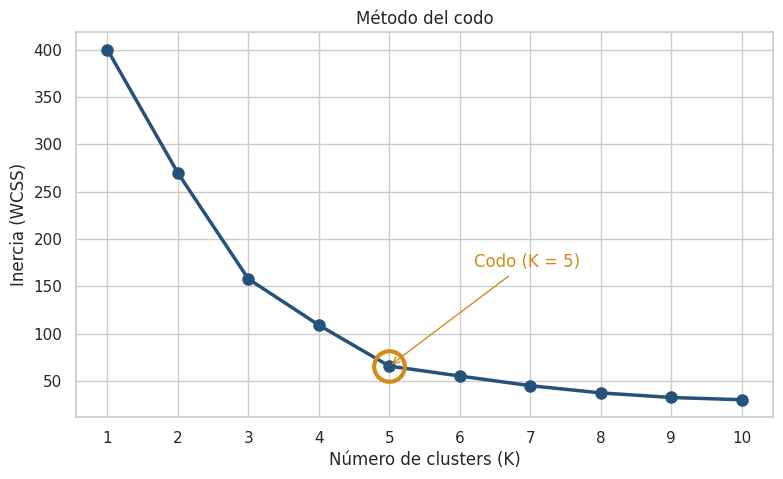

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(list(rango_k), inercias, "o-", color="#24527A", lw=2.5, ms=8)
ax.plot(5, inercias[4], "o", ms=22, mfc="none", mec="#D08C1A", mew=3)
ax.annotate("Codo (K = 5)", xy=(5, inercias[4]), xytext=(6.2, 170),
            arrowprops=dict(arrowstyle="->", color="#D08C1A"), fontsize=12, color="#D08C1A")
ax.set_xticks(list(rango_k))
ax.set_xlabel("Número de clusters (K)")
ax.set_ylabel("Inercia (WCSS)")
ax.set_title("Método del codo")
plt.show()

### ❓ Pregunta 3.1: ¿Por qué valores cercanos a cero indican mejor ajuste?

La inercia suma las distancias al cuadrado entre cada cliente y el centroide de su cluster:

$$WCSS = \sum_{j=1}^{K} \sum_{x_i \in C_j} \lVert x_i - \mu_j \rVert^2$$

Si es cercana a cero, los clientes están **muy pegados a su centroide**, es decir, los grupos son compactos y homogéneos: el centroide representa bien a sus miembros. Un valor alto indica clusters dispersos donde el centroide resume mal a los clientes.

**Ojo:** la inercia **siempre** disminuye al aumentar K, y llega a 0 cuando K = n (cada cliente es su propio cluster), lo cual no sirve de nada. Por eso no se busca el mínimo absoluto, sino el equilibrio entre baja inercia y pocos clusters interpretables.

### ❓ Pregunta 3.2: ¿Cómo se identifica el punto óptimo de K?

Se busca el **"codo"** de la curva: el valor de K a partir del cual agregar más clusters ya no reduce la inercia de forma importante (la curva pasa de caer fuerte a aplanarse). Antes del codo cada cluster extra aporta mucho; después, las mejoras son marginales y solo se fragmentan grupos que ya estaban bien formados.

En la tabla se ve claramente:

- De K = 4 a K = 5 la inercia baja de **108.9 a 65.6** (≈ 40 % de reducción).
- De K = 5 a K = 6 solo baja a **55.1** (≈ 16 %), y de ahí en adelante las reducciones son cada vez menores.

Por lo tanto, el **K óptimo según el codo es 5**.

---
# Parte 4 – Coeficiente de silueta

In [14]:
rango_k_sil = range(2, 11)          # la silueta no está definida para K = 1
siluetas = []
for k in rango_k_sil:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    siluetas.append(silhouette_score(X, km.labels_))

tabla_sil = pd.DataFrame({"K": list(rango_k_sil), "Silueta": np.round(siluetas, 4)})
k_optimo = int(tabla_sil.loc[tabla_sil["Silueta"].idxmax(), "K"])
print("K con mayor silueta:", k_optimo)
with pd.option_context("display.precision", 4):
    display(tabla_sil)

K con mayor silueta: 5


,K,Silueta
0,2,0.3213
1,3,0.4666
2,4,0.4939
3,5,0.5547
4,6,0.5399
5,7,0.5281
6,8,0.4552
7,9,0.4571
8,10,0.4432


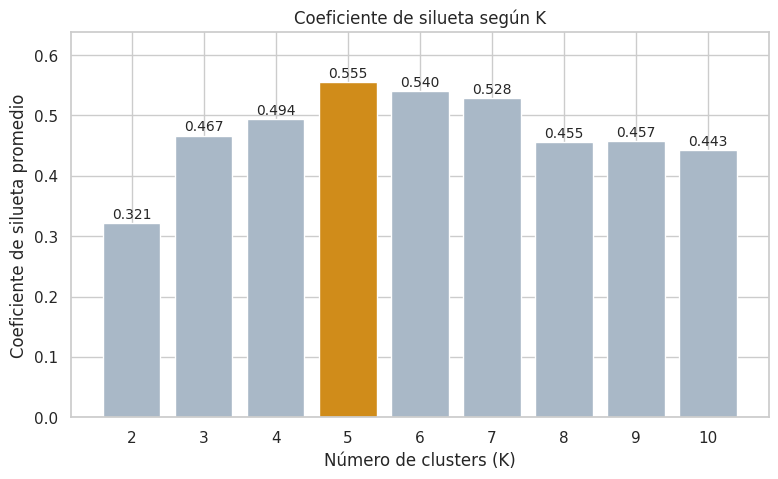

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))
colores_barras = ["#D08C1A" if k == k_optimo else "#A9B8C7" for k in rango_k_sil]
ax.bar(list(rango_k_sil), siluetas, color=colores_barras)
for k, s in zip(rango_k_sil, siluetas):
    ax.text(k, s + 0.008, f"{s:.3f}", ha="center", fontsize=10)
ax.set_xticks(list(rango_k_sil))
ax.set_ylim(0, max(siluetas) * 1.15)
ax.set_xlabel("Número de clusters (K)")
ax.set_ylabel("Coeficiente de silueta promedio")
ax.set_title("Coeficiente de silueta según K")
plt.show()

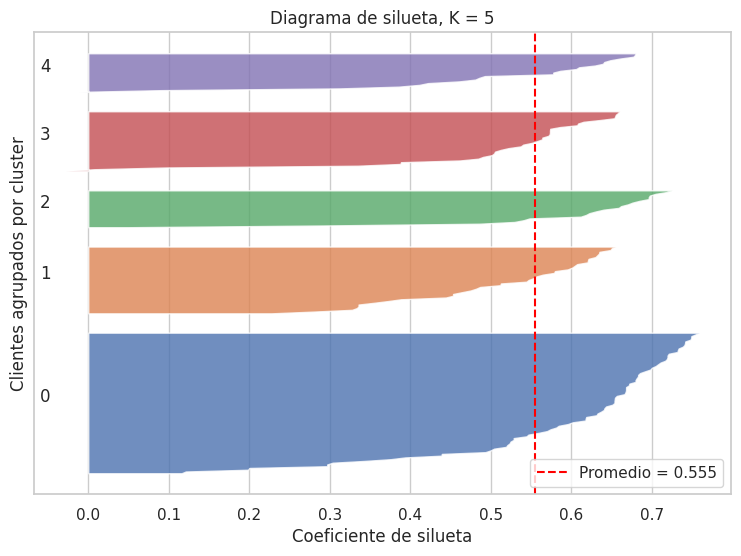

Clientes con silueta negativa: 2 de 200


In [16]:
# Diagrama de silueta por cliente para el K óptimo
km_opt = KMeans(n_clusters=k_optimo, n_init=10, random_state=RANDOM_STATE).fit(X)
valores = silhouette_samples(X, km_opt.labels_)
promedio = valores.mean()

fig, ax = plt.subplots(figsize=(9, 6))
y = 10
for c in range(k_optimo):
    v = np.sort(valores[km_opt.labels_ == c])
    ax.fill_betweenx(np.arange(y, y + len(v)), 0, v, alpha=0.8)
    ax.text(-0.06, y + len(v) / 2, str(c))
    y += len(v) + 10
ax.axvline(promedio, color="red", ls="--", label=f"Promedio = {promedio:.3f}")
ax.set_xlabel("Coeficiente de silueta")
ax.set_ylabel("Clientes agrupados por cluster")
ax.set_yticks([])
ax.set_title(f"Diagrama de silueta, K = {k_optimo}")
ax.legend(loc="lower right")
plt.show()

print("Clientes con silueta negativa:", (valores < 0).sum(), "de", len(valores))

In [17]:
# Comprobación de la Pregunta 1.1: ¿qué pasa si también se usa la edad?
X_con_edad = StandardScaler().fit_transform(df[["Age"] + FEATURES])
comparar = []
for k in rango_k_sil:
    l1 = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X)
    l2 = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_con_edad)
    comparar.append({"K": k, "Ingreso + Gasto": silhouette_score(X, l1),
                     "Edad + Ingreso + Gasto": silhouette_score(X_con_edad, l2)})
with pd.option_context("display.precision", 4):
    display(pd.DataFrame(comparar))

,K,Ingreso + Gasto,Edad + Ingreso + Gasto
0,2,0.3213,0.3355
1,3,0.4666,0.3578
2,4,0.4939,0.4040
3,5,0.5547,0.4166
4,6,0.5399,0.4284
5,7,0.5281,0.4172
6,8,0.4552,0.4082
7,9,0.4571,0.4177
8,10,0.4432,0.4066


### ❓ Pregunta 4.1: ¿Qué mide el coeficiente de silueta?

Mide **qué tan bien asignado está cada punto a su cluster**, comparando su cohesión (qué tan cerca está de los de su propio grupo) con su separación (qué tan lejos está del grupo vecino más cercano). Para cada punto *i*:

$$s(i) = \frac{b(i) - a(i)}{\max\{a(i),\, b(i)\}}$$

- $a(i)$: distancia promedio de *i* a los demás puntos de **su** cluster.
- $b(i)$: distancia promedio de *i* a los puntos del **cluster vecino más cercano**.

El valor va de **-1 a 1**, y el coeficiente del modelo es el promedio de todos los puntos. A diferencia de la inercia, **no mejora automáticamente al subir K**, por eso sirve para elegir el número de clusters.

### ❓ Pregunta 4.2: ¿Qué significa un valor cercano a 1?

Que el punto está **muy cerca de los miembros de su cluster y muy lejos del cluster vecino** ($a(i) \ll b(i)$). Si el promedio se acerca a 1, los grupos son compactos y están claramente separados entre sí: la segmentación es sólida.

Como referencia práctica: > 0.7 estructura fuerte, 0.5–0.7 estructura razonable, 0.25–0.5 estructura débil. Este modelo obtiene **0.555 con K = 5**, una estructura razonable y bien definida para datos reales.

### ❓ Pregunta 4.3: ¿Qué implica un valor cercano a 0 o negativo?

- **Cercano a 0:** el punto está en la **frontera** entre dos clusters ($a(i) \approx b(i)$); podría pertenecer a cualquiera de los dos. Si el promedio es cercano a 0, los clusters se solapan y la segmentación no es clara.
- **Negativo:** el punto está **más cerca de otro cluster que del suyo** ($a(i) > b(i)$), es decir, probablemente está **mal asignado**. Muchos valores negativos indican que el K elegido o las variables usadas no son adecuados.

En el diagrama de silueta de K = 5 solo **2 de 200 clientes** tienen silueta negativa, y apenas por debajo de 0 (≈ -0.01 y -0.03). Son clientes ubicados en el borde entre el grupo promedio y sus vecinos (por ejemplo, ingreso 77 k$ con gasto 36), así que su asignación es dudosa pero no afecta la calidad general del modelo.

### ❓ Pregunta 4.4: ¿Coincide el valor óptimo de K con el método del codo? Justifique.

**Sí, coinciden: ambos métodos indican K = 5.**

- **Codo:** la mayor caída "útil" de inercia ocurre al pasar de 4 a 5 clusters (≈ 40 %) y luego la curva se aplana (≈ 16 % y menos).
- **Silueta:** el máximo es **0.5547 en K = 5**, por encima de K = 4 (0.494) y K = 6 (0.540).

Que dos criterios distintos (uno de compactación y otro de separación) lleguen al mismo resultado da confianza en la elección. Además coincide con lo visto en el diagrama de dispersión de la Parte 1, donde se distinguen 5 nubes de puntos.

La comprobación con la edad muestra que agregarla baja la silueta en casi todos los K (solo en K = 2 queda ligeramente arriba) y su máximo es ≈ 0.43, lejos del 0.55 obtenido sin ella. Esto respalda usar solo ingreso y gasto.

---
# Parte 5 – Modelo K-Means
### 5.1 Entrenar el modelo con el K seleccionado

In [18]:
K = 5
modelo = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE)
modelo.fit(X)

print("Inercia:", round(modelo.inertia_, 2))
print("Silueta:", round(silhouette_score(X, modelo.labels_), 4))
print("Iteraciones hasta converger:", modelo.n_iter_)

Inercia: 65.57
Silueta: 0.5547
Iteraciones hasta converger: 4


### 5.2 Asignar clusters a cada observación

In [19]:
df["Cluster"] = modelo.labels_
print(df["Cluster"].value_counts().sort_index())
df.head(10)

Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4
5,6,Female,22,17,76,2
6,7,Female,35,18,6,4
7,8,Female,23,18,94,2
8,9,Male,64,19,3,4
9,10,Female,30,19,72,2


### 5.3 Obtener los centroides

In [20]:
centroides_escalados = pd.DataFrame(modelo.cluster_centers_, columns=FEATURES)
centroides = pd.DataFrame(scaler.inverse_transform(modelo.cluster_centers_), columns=FEATURES)

print("Centroides en escala estandarizada (z):")
display(centroides_escalados.round(2))
print("Centroides en escala original:")
display(centroides.round(1))

Centroides en escala estandarizada (z):


,Annual Income (k$),Spending Score (1-100)
0,-0.20,-0.03
1,0.99,1.24
2,-1.33,1.13
3,1.06,-1.28
4,-1.31,-1.14


Centroides en escala original:


,Annual Income (k$),Spending Score (1-100)
0,55.3,49.5
1,86.5,82.1
2,25.7,79.4
3,88.2,17.1
4,26.3,20.9


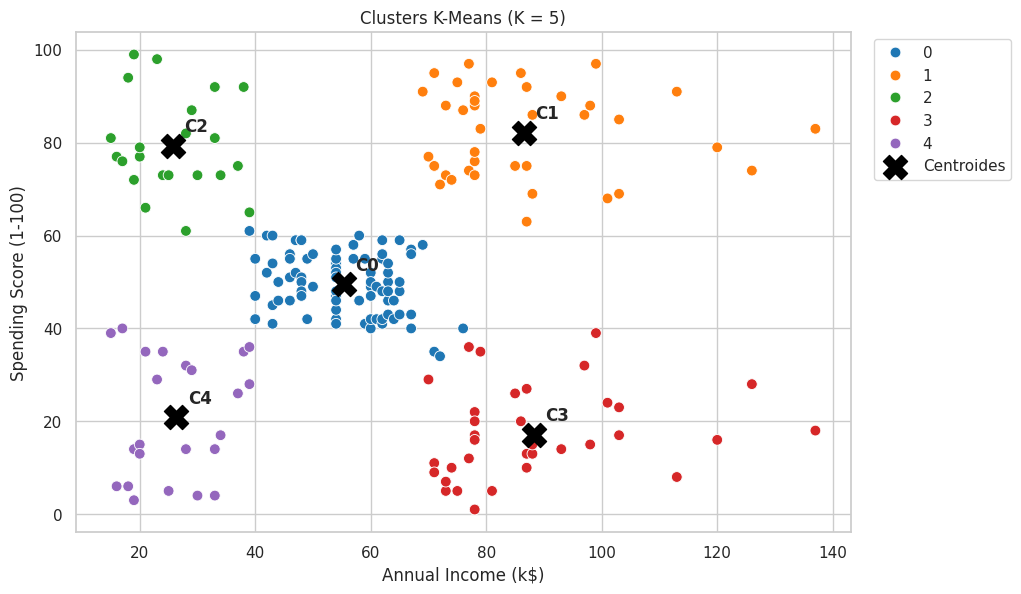

In [21]:
fig, ax = plt.subplots(figsize=(10, 6.5))
sns.scatterplot(data=df, x=FEATURES[0], y=FEATURES[1], hue=df["Cluster"].astype(str),
                hue_order=[str(i) for i in range(K)], palette="tab10", s=60, ax=ax, edgecolor="white")
ax.scatter(centroides[FEATURES[0]], centroides[FEATURES[1]], marker="X", s=300,
           c="black", label="Centroides")
for i, row in centroides.iterrows():
    ax.text(row[FEATURES[0]] + 2, row[FEATURES[1]] + 3, f"C{i}", fontsize=12, weight="bold")
ax.set_title(f"Clusters K-Means (K = {K})")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

In [22]:
resumen = df.groupby("Cluster").agg(
    Clientes=("CustomerID", "count"),
    Ingreso_medio=(FEATURES[0], "mean"),
    Gasto_medio=(FEATURES[1], "mean"),
    Edad_media=("Age", "mean"),
    Pct_mujeres=("Gender", lambda s: 100 * (s == "Female").mean()),
)
resumen["% del total"] = 100 * resumen["Clientes"] / len(df)
resumen.round(1)

,Clientes,Ingreso_medio,Gasto_medio,Edad_media,Pct_mujeres,% del total
Cluster,,,,,,
0,81,55.3,49.5,42.7,59.3,40.5
1,39,86.5,82.1,32.7,53.8,19.5
2,22,25.7,79.4,25.3,59.1,11.0
3,35,88.2,17.1,41.1,45.7,17.5
4,23,26.3,20.9,45.2,60.9,11.5


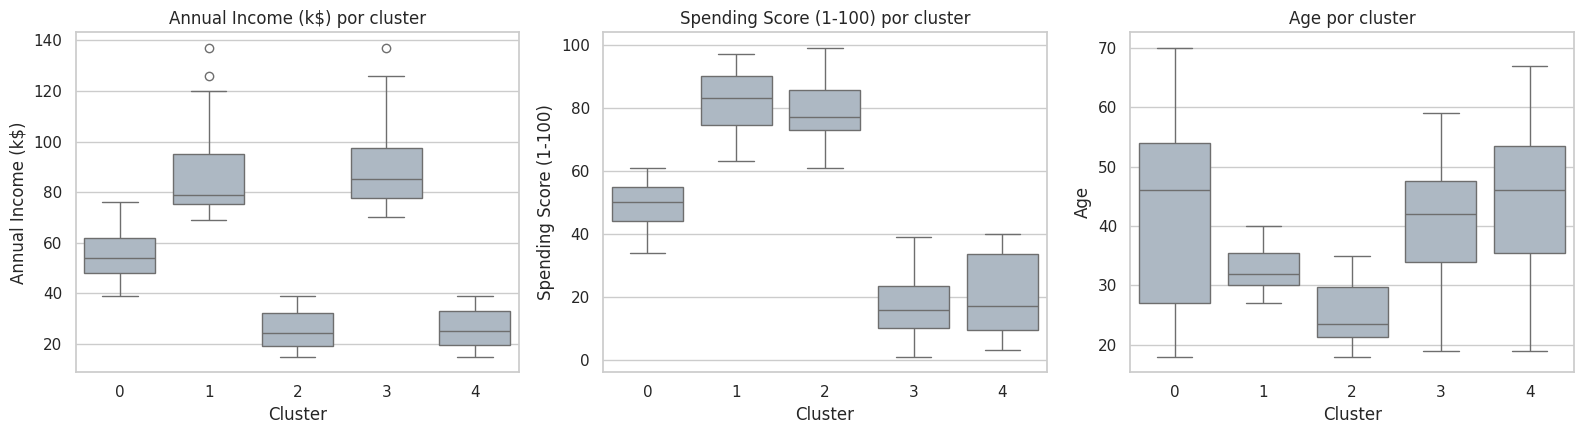

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ["Annual Income (k$)", "Spending Score (1-100)", "Age"]):
    sns.boxplot(data=df, x="Cluster", y=col, color="#A9B8C7", ax=ax)
    ax.set_title(f"{col} por cluster")
plt.tight_layout()
plt.show()

### ❓ Pregunta 5.1: ¿Qué representa cada cluster?

Cada cluster es un **grupo de clientes con un comportamiento de compra similar**, definido por la combinación de su ingreso anual y su puntaje de gasto. El **centroide** es el "cliente típico" del grupo: el promedio de ingreso y gasto de sus miembros.

Leyendo los centroides en escala original (los números de cluster pueden variar según la versión de scikit-learn, por eso se describen por su posición):

| Grupo | Ingreso medio | Gasto medio | Clientes | Qué representa |
|---|---|---|---|---|
| Ingreso medio, gasto medio | ≈ 55 k$ | ≈ 50 | 81 (40.5 %) | El cliente "típico" del centro comercial |
| Ingreso alto, gasto alto | ≈ 87 k$ | ≈ 82 | 39 (19.5 %) | Clientes con dinero que sí lo gastan aquí |
| Ingreso alto, gasto bajo | ≈ 88 k$ | ≈ 17 | 35 (17.5 %) | Clientes con dinero que casi no compran |
| Ingreso bajo, gasto alto | ≈ 26 k$ | ≈ 79 | 22 (11 %) | Clientes que gastan más de lo que su ingreso sugiere |
| Ingreso bajo, gasto bajo | ≈ 26 k$ | ≈ 21 | 23 (11.5 %) | Clientes con poca capacidad y poco gasto |

### ❓ Pregunta 5.2: ¿Qué diferencias existen entre los grupos obtenidos?

- **Ingreso:** separa claramente tres niveles (≈ 26, ≈ 55 y ≈ 87 k$). Los grupos de ingreso alto y bajo se dividen a su vez en dos según el gasto.
- **Gasto:** la diferencia más fuerte está entre los dos grupos de ingreso alto: tienen casi el mismo ingreso (≈ 87–88 k$) pero gastan **82 vs. 17**. Lo mismo pasa con los de ingreso bajo (**79 vs. 21**). Es decir, el ingreso **no explica** el gasto; es el comportamiento lo que los diferencia.
- **Edad (variable descriptiva, no usada en el modelo):** los grupos que más gastan son los más jóvenes (≈ 25 años en ingreso bajo/gasto alto y ≈ 33 en ingreso alto/gasto alto), mientras que los que gastan poco rondan los 41–45 años. Esto confirma la relación negativa edad-gasto de la Parte 1.
- **Tamaño:** el grupo promedio concentra el 40 % de los clientes; los otros cuatro tienen entre 22 y 39 clientes cada uno.
- **Dispersión:** el grupo promedio es el más compacto; los de ingreso alto son más dispersos en el eje del ingreso (ahí están los dos clientes de 137 k$).

---
# Parte 6 – Interpretación de negocio
Se asigna un perfil a cada cluster según la posición de su centroide (en unidades estandarizadas) respecto a la media del dataset. El taller propone cuatro perfiles; el quinto grupo (ingreso bajo con gasto alto) no encaja en ninguno, así que se nombra **Clientes impulsivos**.

In [24]:
def asignar_perfil(z_ingreso, z_gasto, umbral=0.5):
    if abs(z_ingreso) < umbral and abs(z_gasto) < umbral:
        return "Clientes promedio"
    if z_ingreso >= 0 and z_gasto >= 0:
        return "Clientes de alto valor"
    if z_ingreso >= 0 and z_gasto < 0:
        return "Clientes con potencial"
    if z_ingreso < 0 and z_gasto < 0:
        return "Clientes de bajo valor"
    return "Clientes impulsivos"

mapa_perfiles = {i: asignar_perfil(*modelo.cluster_centers_[i]) for i in range(K)}
df["Perfil"] = df["Cluster"].map(mapa_perfiles)

perfiles = resumen.copy()
perfiles.insert(0, "Perfil", perfiles.index.map(mapa_perfiles))
perfiles.sort_values("Gasto_medio", ascending=False).round(1)

,Perfil,Clientes,Ingreso_medio,Gasto_medio,Edad_media,Pct_mujeres,% del total
Cluster,,,,,,,
1,Clientes de alto valor,39,86.5,82.1,32.7,53.8,19.5
2,Clientes impulsivos,22,25.7,79.4,25.3,59.1,11.0
0,Clientes promedio,81,55.3,49.5,42.7,59.3,40.5
4,Clientes de bajo valor,23,26.3,20.9,45.2,60.9,11.5
3,Clientes con potencial,35,88.2,17.1,41.1,45.7,17.5


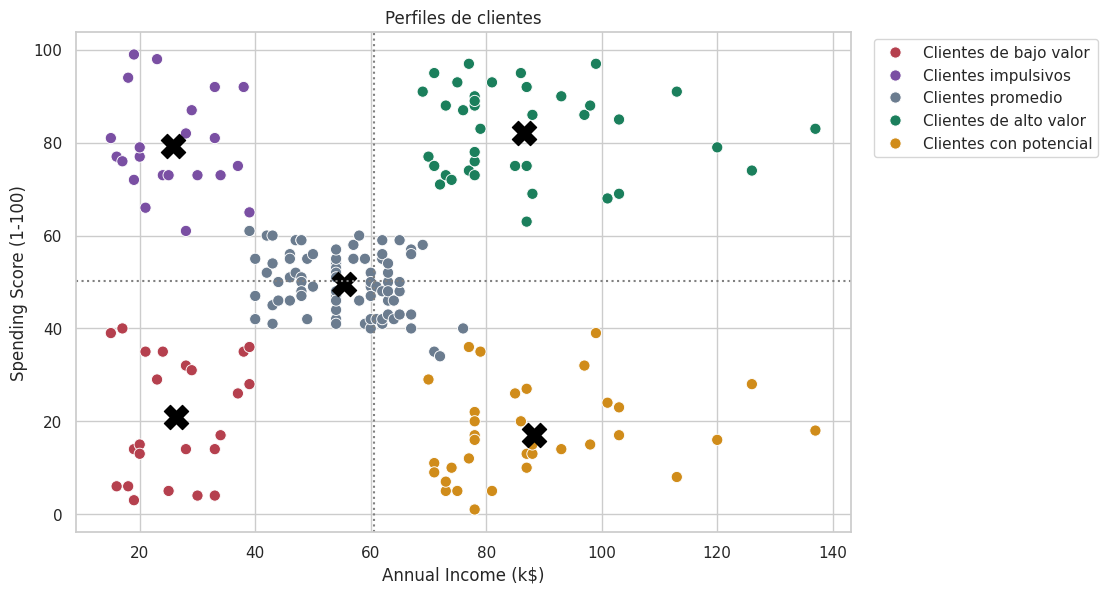

In [25]:
fig, ax = plt.subplots(figsize=(10, 6.5))
sns.scatterplot(data=df, x=FEATURES[0], y=FEATURES[1], hue="Perfil",
                palette=COLORES, s=65, ax=ax, edgecolor="white")
ax.scatter(centroides[FEATURES[0]], centroides[FEATURES[1]], marker="X", s=300, c="black")
ax.axhline(df[FEATURES[1]].mean(), ls=":", c="grey")
ax.axvline(df[FEATURES[0]].mean(), ls=":", c="grey")
ax.set_title("Perfiles de clientes")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

In [26]:
# Guardar el dataset con su segmento asignado
RUTA_SALIDA = RUTA_DATOS.parent / "clientes_segmentados.csv"
df.to_csv(RUTA_SALIDA, index=False)
print("Guardado en", RUTA_SALIDA)

Guardado en ../datos/clientes_segmentados.csv


### ❓ Pregunta 6.1: ¿Qué estrategias de marketing se podrían aplicar a cada grupo?

| Perfil | Quiénes son | Estrategia | Objetivo |
|---|---|---|---|
| **Clientes de alto valor** (ingreso ≈ 87 k$, gasto ≈ 82, ≈ 33 años) | Los mejores clientes | Programa VIP y de fidelización, preventas y lanzamientos exclusivos, atención personalizada, beneficios por referir amigos. | **Retener** y evitar que se vayan a la competencia. |
| **Clientes con potencial** (ingreso ≈ 88 k$, gasto ≈ 17, ≈ 41 años) | Tienen dinero pero no lo gastan aquí | Campañas de calidad y marcas premium, experiencias (eventos, servicios), incentivos de primera compra, encuestas para entender por qué no compran. Comunicar valor, no descuentos. | **Activar** y aumentar su gasto. |
| **Clientes promedio** (ingreso ≈ 55 k$, gasto ≈ 50, ≈ 43 años) | El grupo más grande (40 %) | Promociones de temporada, combos, programa de puntos, venta cruzada y recomendaciones para subir el ticket promedio. | **Aumentar frecuencia y ticket**. |
| **Clientes impulsivos** (ingreso ≈ 26 k$, gasto ≈ 79, ≈ 25 años) | Jóvenes que gastan mucho para su ingreso | Marketing en redes sociales e influencers, tendencias, *flash sales*, compra a cuotas. Cuidar no fomentar sobreendeudamiento. | **Mantener la frecuencia** con buena relación precio-tendencia. |
| **Clientes de bajo valor** (ingreso ≈ 26 k$, gasto ≈ 21, ≈ 45 años) | Poca capacidad y poco gasto | Canales de bajo costo (email, WhatsApp), ofertas en productos básicos, descuentos por volumen. No invertir mucho en publicidad para este grupo. | **Mantener** con costo mínimo. |

### ❓ Pregunta 6.2: ¿Qué segmento representa mayor oportunidad de crecimiento?

Los **Clientes con potencial** (ingreso alto ≈ 88 k$ y gasto bajo ≈ 17, 35 clientes).

- Tienen **casi el mismo ingreso que los clientes de alto valor**, pero su gasto es casi **5 veces menor**. La capacidad de compra ya existe; lo que falta es convertirla en ventas en el centro comercial.
- Si una parte de ellos se moviera hacia el comportamiento del grupo de alto valor, el aumento en ventas sería mucho mayor que el que se puede lograr con los grupos de ingreso bajo, que no tienen margen económico.
- Al ser personas de ≈ 41 años, probablemente valoran la calidad, la comodidad y el servicio más que los descuentos, así que la estrategia debe ir por ahí.

Como oportunidad secundaria están los **Clientes promedio**: aunque cada uno tiene menos margen, son el 40 % de la base, así que un aumento pequeño en su ticket tiene un gran efecto total.

---
# Parte 7 – Despliegue con Streamlit
La aplicación está en `frontend/app.py` y consume los artefactos generados en `modelo/`. Permite:

1. **Visualizar el método del codo** (y la gráfica de silueta).
2. **Mostrar los clusters generados** con sus centroides, perfiles y estrategias.
3. **Ingresar un nuevo cliente** (ingreso anual y puntaje de gasto).
4. **Clasificarlo automáticamente** en un cluster, mostrando su perfil, la estrategia recomendada y su ubicación en la gráfica.

Para ejecutarla, desde la carpeta raíz del proyecto:

```bash
python entrenamiento/entrenar.py     # genera el modelo (si no existe)
streamlit run frontend/app.py
```

### 7.1 Exportar el modelo
La siguiente celda ejecuta el script de la capa de entrenamiento, que repite este mismo proceso (K = 5) y guarda el modelo, el scaler y los metadatos en `modelo/`.

In [27]:
%run ../entrenamiento/entrenar.py --k 5

[1/5] Cargando datos desde /home/claude/taller_kmeans/datos/Mall_Customers.csv
[2/5] Escalando variables con StandardScaler
[3/5] Evaluando K con método del codo y coeficiente de silueta
      K= 1  inercia=  400.00  silueta=  -   
      K= 2  inercia=  269.69  silueta=0.3213
      K= 3  inercia=  157.70  silueta=0.4666
      K= 4  inercia=  108.92  silueta=0.4939
      K= 5  inercia=   65.57  silueta=0.5547  <- K elegido
      K= 6  inercia=   55.06  silueta=0.5399
      K= 7  inercia=   44.86  silueta=0.5281
      K= 8  inercia=   37.23  silueta=0.4552
      K= 9  inercia=   32.39  silueta=0.4571
      K=10  inercia=   29.98  silueta=0.4432
[4/5] Entrenando K-Means final con K=5
[5/5] Guardando artefactos

Resumen de clusters:
  Cluster 0: Clientes promedio        n= 81 ingreso=  55.3k$  gasto= 49.5
  Cluster 1: Clientes de alto valor   n= 39 ingreso=  86.5k$  gasto= 82.1
  Cluster 2: Clientes impulsivos      n= 22 ingreso=  25.7k$  gasto= 79.4
  Cluster 3: Clientes con potencial   n

### 7.2 Prueba: clasificar clientes nuevos con el modelo exportado

In [28]:
import joblib

modelo_cargado = joblib.load("../modelo/kmeans_model.joblib")
scaler_cargado = joblib.load("../modelo/scaler.joblib")

nuevos = pd.DataFrame({
    "Annual Income (k$)":     [95, 20, 60, 85, 25],
    "Spending Score (1-100)": [15, 85, 50, 90, 10],
})
nuevos["Cluster"] = modelo_cargado.predict(scaler_cargado.transform(nuevos[FEATURES]))
nuevos["Perfil"] = [asignar_perfil(*modelo_cargado.cluster_centers_[c]) for c in nuevos["Cluster"]]
nuevos

,Annual Income (k$),Spending Score (1-100),Cluster,Perfil
0,95,15,3,Clientes con potencial
1,20,85,2,Clientes impulsivos
2,60,50,0,Clientes promedio
3,85,90,1,Clientes de alto valor
4,25,10,4,Clientes de bajo valor


---
# Conclusiones

- Las variables **ingreso anual** y **puntaje de gasto** son suficientes para obtener una segmentación clara; la edad y el género sirven mejor para describir los grupos que para formarlos.
- El **método del codo** y el **coeficiente de silueta** coinciden en **K = 5**, con una silueta de 0.555, lo que indica grupos razonablemente compactos y separados.
- Se identificaron cinco perfiles: alto valor, con potencial, promedio, impulsivos y bajo valor. El ingreso no determina el gasto: dentro de un mismo nivel de ingreso hay clientes que gastan mucho y otros que casi no compran.
- La mayor oportunidad de crecimiento está en los **clientes con potencial** (ingreso alto, gasto bajo).
- El modelo quedó desplegado en una aplicación Streamlit que clasifica clientes nuevos en tiempo real, lo que permite al equipo de marketing aplicar la estrategia correspondiente desde el primer contacto.